# SIMULACIÓN INVERSIÓN 100€ MENSUALES EN ACTIVOS: SP&500, IBEX 35, ORO, BITCOIN, NVIDIA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Cargamos los precios mensuales de los activos
precios = pd.read_csv(
    "datos/precios_mensuales_eur.csv",
    index_col="fecha",
    parse_dates=True
)

# Cargamos los datos del IPC
ipc = pd.read_csv(
    "datos/ipc_espana_limpio.csv",
    parse_dates=["fecha"]
)

# Mostramos las dimensiones de ambos archivos
print("Dimensiones de precios:", precios.shape)
print("Dimensiones del IPC:", ipc.shape)

Dimensiones de precios: (201, 6)
Dimensiones del IPC: (201, 3)


In [3]:
# Convertimos el índice de precios en una columna para compararlo
fechas_precios = pd.DatetimeIndex(precios.index)

# Extraemos las fechas del IPC
fechas_ipc = pd.DatetimeIndex(ipc["fecha"])

# Comprobamos si coinciden
print("¿Coinciden las fechas?:", fechas_precios.equals(fechas_ipc))

print("Primer mes de los precios:", fechas_precios.min())
print("Último mes de los precios:", fechas_precios.max())

print("Primer mes del IPC:", fechas_ipc.min())
print("Último mes del IPC:", fechas_ipc.max())

¿Coinciden las fechas?: True
Primer mes de los precios: 2010-01-01 00:00:00
Último mes de los precios: 2026-09-01 00:00:00
Primer mes del IPC: 2010-01-01 00:00:00
Último mes del IPC: 2026-09-01 00:00:00


# SIMULACIÓN SP&500

In [4]:
def simular_inversion(precios_activo, aportacion=100):

    # Eliminamos los meses en los que no hay precio disponible
    precios_activo = precios_activo.dropna()

    # Calculamos cuántas participaciones compramos cada mes
    participaciones_compradas = aportacion / precios_activo

    # Acumulamos todas las participaciones compradas
    participaciones_acumuladas = participaciones_compradas.cumsum()

    # Calculamos el valor de nuestra inversión cada mes
    valor_cartera = participaciones_acumuladas * precios_activo

    # Calculamos cuánto dinero hemos aportado hasta cada mes
    dinero_aportado = pd.Series(
        aportacion,
        index=precios_activo.index
    ).cumsum()

    # Calculamos la ganancia o pérdida
    ganancia = valor_cartera - dinero_aportado

    # Guardamos los resultados en una tabla
    resultado = pd.DataFrame({
        "precio": precios_activo,
        "participaciones_compradas": participaciones_compradas,
        "participaciones_acumuladas": participaciones_acumuladas,
        "dinero_aportado": dinero_aportado,
        "valor_cartera": valor_cartera,
        "ganancia": ganancia
    })

    return resultado

In [5]:
# Simulamos una inversión de 100 € mensuales en el S&P 500
resultado_sp500 = simular_inversion(precios["sp500"])

# Mostramos los primeros cinco meses
display(resultado_sp500.head())

,precio,participaciones_compradas,participaciones_acumuladas,dinero_aportado,valor_cartera,ganancia
fecha,,,,,,
2010-01-01,773.852156,0.129224,0.129224,100,100.000000,0.000000
2010-02-01,809.867281,0.123477,0.252701,200,204.654006,4.654006
2010-03-01,865.729066,0.115510,0.368210,300,318.770316,18.770316
2010-04-01,892.378983,0.112060,0.480270,400,428.583089,28.583089
2010-05-01,886.572800,0.112794,0.593064,500,525.794552,25.794552


In [6]:
# Obtenemos los resultados del último mes disponible
ultimo_mes = resultado_sp500.iloc[-1]

print("RESULTADOS DE LA INVERSIÓN EN EL S&P 500")
print("----------------------------------------")

print("Fecha final:", resultado_sp500.index[-1].strftime("%m/%Y"))

print("Meses invertidos:", len(resultado_sp500))

print("Total aportado:", round(ultimo_mes["dinero_aportado"], 2), "€")

print("Valor final de la cartera:", round(ultimo_mes["valor_cartera"], 2), "€")

print("Ganancia:", round(ultimo_mes["ganancia"], 2), "€")

RESULTADOS DE LA INVERSIÓN EN EL S&P 500
----------------------------------------
Fecha final: 09/2026
Meses invertidos: 201
Total aportado: 20100.0 €
Valor final de la cartera: 70211.7 €
Ganancia: 50111.7 €


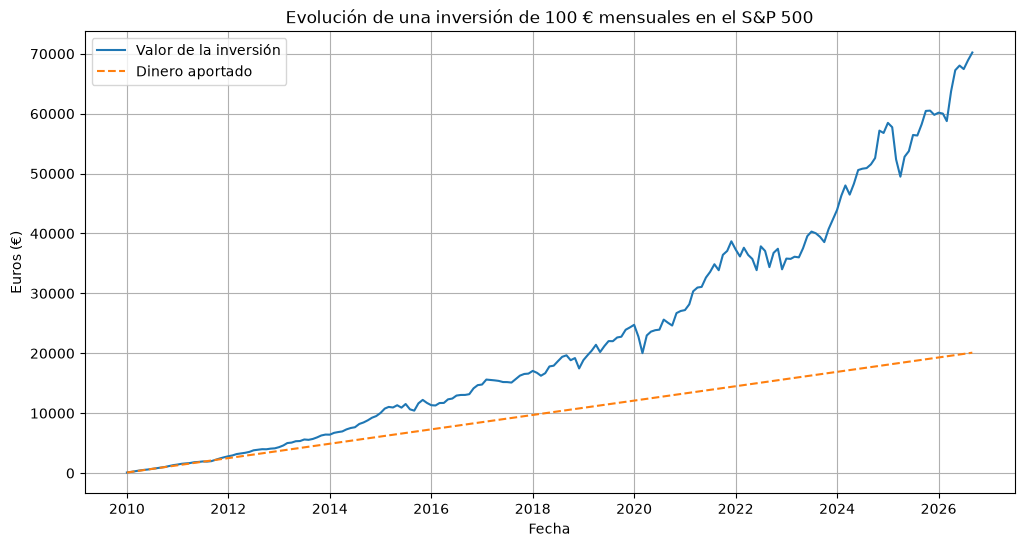

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    resultado_sp500.index,
    resultado_sp500["valor_cartera"],
    label="Valor de la inversión"
)

plt.plot(
    resultado_sp500.index,
    resultado_sp500["dinero_aportado"],
    label="Dinero aportado",
    linestyle="--"
)

plt.title("Evolución de una inversión de 100 € mensuales en el S&P 500")
plt.xlabel("Fecha")
plt.ylabel("Euros (€)")
plt.legend()
plt.grid(True)
plt.show()

# SIMULACIÓN IBEX 35

In [12]:
# Simulamos una inversión de 100 € mensuales en el IBEX 35
resultado_ibex = simular_inversion(precios["ibex35"])

# Mostramos los primeros cinco meses
display(resultado_ibex.head())

,precio,participaciones_compradas,participaciones_acumuladas,dinero_aportado,valor_cartera,ganancia
fecha,,,,,,
2010-01-01,10947.689453,0.009134,0.009134,100,100.000000,0.000000
2010-02-01,10333.588867,0.009677,0.018812,200,194.390592,-5.609408
2010-03-01,10871.289062,0.009199,0.028010,300,304.505554,4.505554
2010-04-01,10492.189453,0.009531,0.037541,400,393.886948,-6.113052
2010-05-01,9359.390625,0.010684,0.048225,500,451.360583,-48.639417


In [13]:
# Obtenemos los resultados del último mes disponible
ultimo_mes = resultado_ibex.iloc[-1]

print("RESULTADOS DE LA INVERSIÓN EN EL IBEX 35")
print("----------------------------------------")

print("Fecha de inicio:", resultado_ibex.index[0].strftime("%m/%Y"))

print("Fecha final:", resultado_ibex.index[-1].strftime("%m/%Y"))

print("Meses invertidos:", len(resultado_ibex))

print("Total aportado:", round(ultimo_mes["dinero_aportado"], 2), "€")

print("Valor final de la cartera:", round(ultimo_mes["valor_cartera"], 2), "€")

print("Ganancia:", round(ultimo_mes["ganancia"], 2), "€")

RESULTADOS DE LA INVERSIÓN EN EL IBEX 35
----------------------------------------
Fecha de inicio: 01/2010
Fecha final: 09/2026
Meses invertidos: 201
Total aportado: 20100.0 €
Valor final de la cartera: 40671.44 €
Ganancia: 20571.44 €


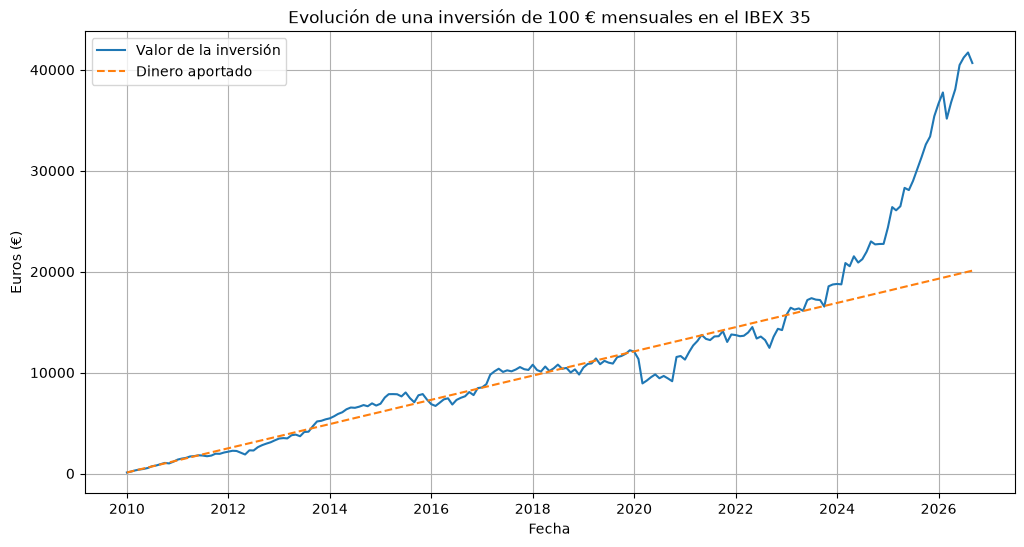

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    resultado_ibex.index,
    resultado_ibex["valor_cartera"],
    label="Valor de la inversión"
)

plt.plot(
    resultado_ibex.index,
    resultado_ibex["dinero_aportado"],
    label="Dinero aportado",
    linestyle="--"
)

plt.title("Evolución de una inversión de 100 € mensuales en el IBEX 35")
plt.xlabel("Fecha")
plt.ylabel("Euros (€)")
plt.legend()
plt.grid(True)
plt.show()

# SIMULACIÓN ORO

In [15]:
# Simulamos una inversión de 100 € mensuales en oro
resultado_oro = simular_inversion(precios["oro"])

# Mostramos los primeros cinco meses
display(resultado_oro.head())

,precio,participaciones_compradas,participaciones_acumuladas,dinero_aportado,valor_cartera,ganancia
fecha,,,,,,
2010-01-01,24.930000,4.011231,4.011231,100,100.000000,0.000000
2010-02-01,26.290001,3.803728,7.814959,200,205.455277,5.455277
2010-03-01,26.500000,3.773585,11.588544,300,307.096411,7.096411
2010-04-01,28.600000,3.496503,15.085047,400,431.432358,31.432358
2010-05-01,31.860001,3.138732,18.223779,500,580.609615,80.609615


In [16]:
# Obtenemos los resultados del último mes disponible
ultimo_mes = resultado_oro.iloc[-1]

print("RESULTADOS DE LA INVERSIÓN EN ORO")
print("---------------------------------")

print("Fecha de inicio:", resultado_oro.index[0].strftime("%m/%Y"))

print("Fecha final:", resultado_oro.index[-1].strftime("%m/%Y"))

print("Meses invertidos:", len(resultado_oro))

print("Total aportado:", round(ultimo_mes["dinero_aportado"], 2), "€")

print("Valor final de la cartera:", round(ultimo_mes["valor_cartera"], 2), "€")

print("Ganancia:", round(ultimo_mes["ganancia"], 2), "€")

RESULTADOS DE LA INVERSIÓN EN ORO
---------------------------------
Fecha de inicio: 01/2010
Fecha final: 09/2026
Meses invertidos: 201
Total aportado: 20100.0 €
Valor final de la cartera: 55642.07 €
Ganancia: 35542.07 €


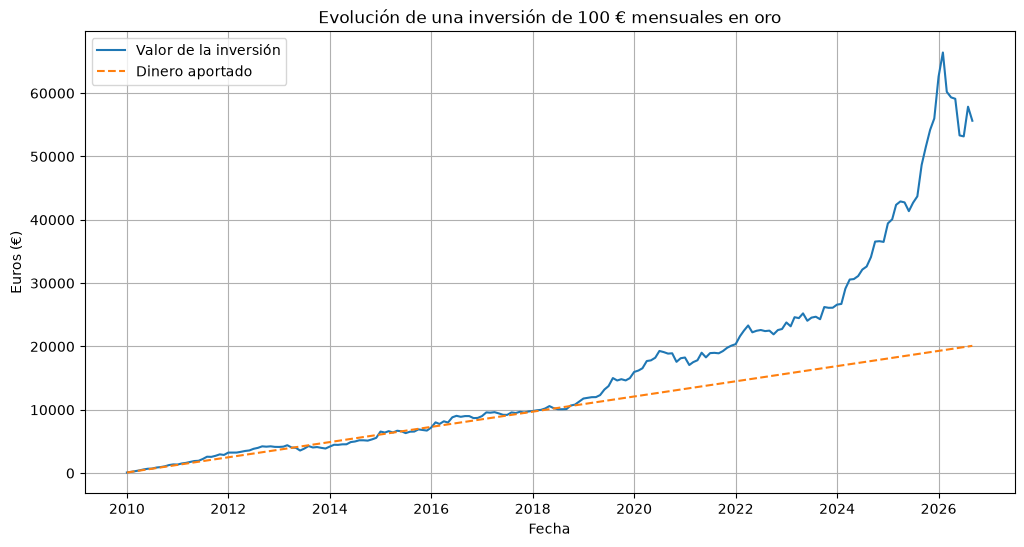

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    resultado_oro.index,
    resultado_oro["valor_cartera"],
    label="Valor de la inversión"
)

plt.plot(
    resultado_oro.index,
    resultado_oro["dinero_aportado"],
    label="Dinero aportado",
    linestyle="--"
)

plt.title("Evolución de una inversión de 100 € mensuales en oro")
plt.xlabel("Fecha")
plt.ylabel("Euros (€)")
plt.legend()
plt.grid(True)
plt.show()

# SIMULACIÓN BITCOIN 2014

In [18]:
# Simulamos una inversión de 100 € mensuales en Bitcoin
resultado_bitcoin = simular_inversion(precios["bitcoin"])

# Mostramos los primeros cinco meses
display(resultado_bitcoin.head())

,precio,participaciones_compradas,participaciones_acumuladas,dinero_aportado,valor_cartera,ganancia
fecha,,,,,,
2014-09-01,306.417480,0.326352,0.326352,100,100.000000,0.000000
2014-10-01,270.138153,0.370181,0.696533,200,188.160164,-11.839836
2014-11-01,304.018494,0.328927,1.025460,300,311.758942,11.758942
2014-12-01,264.709808,0.377772,1.403233,400,371.449440,-28.550560
2015-01-01,192.684753,0.518982,1.922215,500,370.381533,-129.618467


In [19]:
# Obtenemos los resultados del último mes disponible
ultimo_mes = resultado_bitcoin.iloc[-1]

print("RESULTADOS DE LA INVERSIÓN EN BITCOIN")
print("-------------------------------------")

print("Fecha de inicio:", resultado_bitcoin.index[0].strftime("%m/%Y"))

print("Fecha final:", resultado_bitcoin.index[-1].strftime("%m/%Y"))

print("Meses invertidos:", len(resultado_bitcoin))

print("Total aportado:", round(ultimo_mes["dinero_aportado"], 2), "€")

print("Valor final de la cartera:", round(ultimo_mes["valor_cartera"], 2), "€")

print("Ganancia:", round(ultimo_mes["ganancia"], 2), "€")

RESULTADOS DE LA INVERSIÓN EN BITCOIN
-------------------------------------
Fecha de inicio: 09/2014
Fecha final: 09/2026
Meses invertidos: 145
Total aportado: 14500.0 €
Valor final de la cartera: 749032.43 €
Ganancia: 734532.43 €


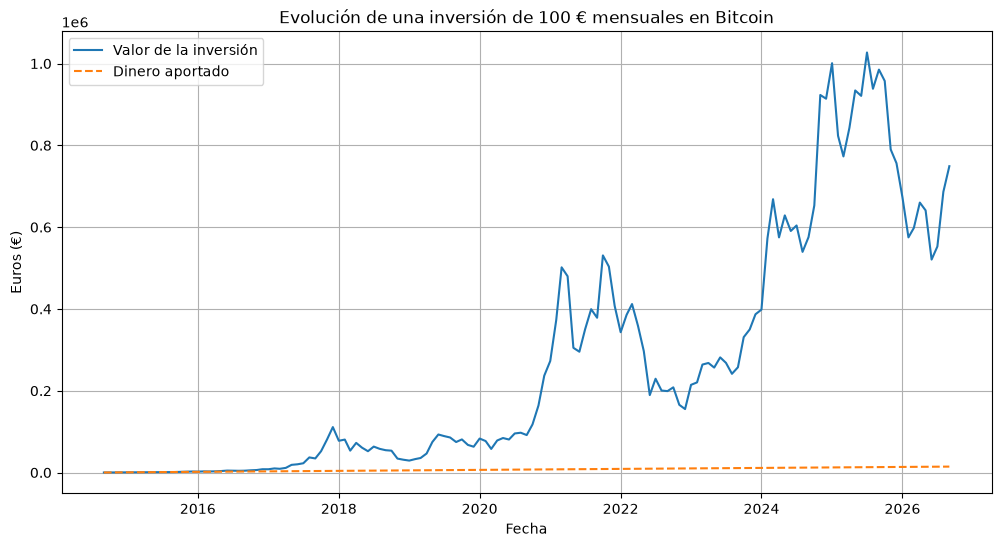

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    resultado_bitcoin.index,
    resultado_bitcoin["valor_cartera"],
    label="Valor de la inversión"
)

plt.plot(
    resultado_bitcoin.index,
    resultado_bitcoin["dinero_aportado"],
    label="Dinero aportado",
    linestyle="--"
)

plt.title("Evolución de una inversión de 100 € mensuales en Bitcoin")
plt.xlabel("Fecha")
plt.ylabel("Euros (€)")
plt.legend()
plt.grid(True)
plt.show()

# SIMULACIÓN NVIDIA

In [21]:
# Simulamos una inversión de 100 € mensuales en Nvidia
resultado_nvidia = simular_inversion(precios["nvidia"])

# Mostramos los primeros cinco meses
display(resultado_nvidia.head())

,precio,participaciones_compradas,participaciones_acumuladas,dinero_aportado,valor_cartera,ganancia
fecha,,,,,,
2010-01-01,0.253607,394.311342,394.311342,100,100.000000,0.000000
2010-02-01,0.271633,368.143427,762.454769,200,207.108076,7.108076
2010-03-01,0.294559,339.490073,1101.944841,300,324.588237,24.588237
2010-04-01,0.270150,370.165371,1472.110212,400,397.689878,-2.310122
2010-05-01,0.244531,408.945744,1881.055957,500,459.976900,-40.023100


In [22]:
# Obtenemos los resultados del último mes disponible
ultimo_mes = resultado_nvidia.iloc[-1]

print("RESULTADOS DE LA INVERSIÓN EN NVIDIA")
print("------------------------------------")

print("Fecha de inicio:", resultado_nvidia.index[0].strftime("%m/%Y"))

print("Fecha final:", resultado_nvidia.index[-1].strftime("%m/%Y"))

print("Meses invertidos:", len(resultado_nvidia))

print("Total aportado:", round(ultimo_mes["dinero_aportado"], 2), "€")

print("Valor final de la cartera:", round(ultimo_mes["valor_cartera"], 2), "€")

print("Ganancia:", round(ultimo_mes["ganancia"], 2), "€")

RESULTADOS DE LA INVERSIÓN EN NVIDIA
------------------------------------
Fecha de inicio: 01/2010
Fecha final: 09/2026
Meses invertidos: 201
Total aportado: 20100.0 €
Valor final de la cartera: 5682786.55 €
Ganancia: 5662686.55 €


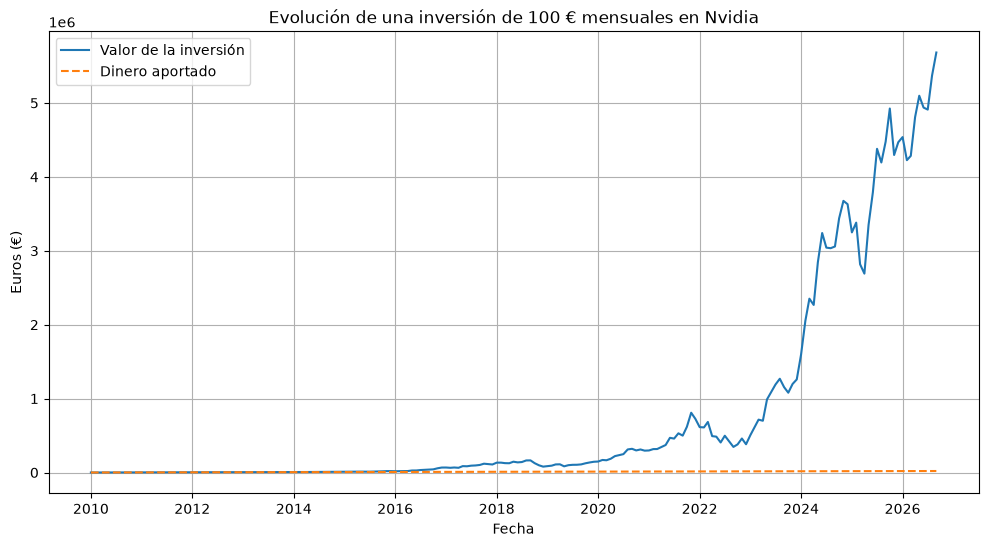

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(
    resultado_nvidia.index,
    resultado_nvidia["valor_cartera"],
    label="Valor de la inversión"
)

plt.plot(
    resultado_nvidia.index,
    resultado_nvidia["dinero_aportado"],
    label="Dinero aportado",
    linestyle="--"
)

plt.title("Evolución de una inversión de 100 € mensuales en Nvidia")
plt.xlabel("Fecha")
plt.ylabel("Euros (€)")
plt.legend()
plt.grid(True)
plt.show()

# COMPARACIÓN CONJUNTO DE ACTIVOS

In [25]:
# Guardamos las simulaciones individuales de cada activo
resultados = {}

for activo in ["sp500", "ibex35", "oro", "bitcoin", "nvidia"]:
    resultados[activo] = simular_inversion(precios[activo])

print("Activos simulados:")
for activo in resultados:
    print("-", activo)

Activos simulados:
- sp500
- ibex35
- oro
- bitcoin
- nvidia


In [26]:
# Definimos el periodo común de comparación
fecha_inicio_comun = "2015-01-01"
fecha_final_comun = "2026-09-01"

# Guardamos las simulaciones de todos los activos
resultados_comunes = {}

# Simulamos una inversión de 100 € mensuales en cada activo
for activo in ["sp500", "ibex35", "oro", "bitcoin", "nvidia"]:

    precios_periodo = precios.loc[
        fecha_inicio_comun:fecha_final_comun, activo
    ]

    resultados_comunes[activo] = simular_inversion(precios_periodo)

# Comprobamos que todos tienen el mismo periodo
for activo, resultado in resultados_comunes.items():
    print(
        activo,
        "| Meses:", len(resultado),
        "| Inicio:", resultado.index[0].strftime("%m/%Y"),
        "| Final:", resultado.index[-1].strftime("%m/%Y")
    )

sp500 | Meses: 141 | Inicio: 01/2015 | Final: 09/2026
ibex35 | Meses: 141 | Inicio: 01/2015 | Final: 09/2026
oro | Meses: 141 | Inicio: 01/2015 | Final: 09/2026
bitcoin | Meses: 141 | Inicio: 01/2015 | Final: 09/2026
nvidia | Meses: 141 | Inicio: 01/2015 | Final: 09/2026


In [27]:
# Creamos una lista para guardar los resultados
resumen_comun = []

# Recorremos las simulaciones de cada activo
for activo, resultado in resultados_comunes.items():

    ultimo_mes = resultado.iloc[-1]

    total_aportado = ultimo_mes["dinero_aportado"]
    valor_final = ultimo_mes["valor_cartera"]
    ganancia = ultimo_mes["ganancia"]

    rentabilidad = (ganancia / total_aportado) * 100

    resumen_comun.append({
        "activo": activo,
        "fecha_inicio": resultado.index[0],
        "fecha_final": resultado.index[-1],
        "meses_invertidos": len(resultado),
        "total_aportado": total_aportado,
        "valor_final": valor_final,
        "ganancia": ganancia,
        "rentabilidad_pct": rentabilidad
    })

# Convertimos los resultados en una tabla
tabla_comparativa = pd.DataFrame(resumen_comun)

# Ordenamos los activos de mayor a menor valor final
tabla_comparativa = tabla_comparativa.sort_values(
    "valor_final", ascending=False
)

# Redondeamos los resultados a dos decimales
tabla_comparativa = tabla_comparativa.round(2)

display(tabla_comparativa)

/var/folders/85/jy3c88hd5s71n8s3cw2bq_900000gn/T/ipykernel_72948/1800578307.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tabla_comparativa = tabla_comparativa.round(2)


,activo,fecha_inicio,fecha_final,meses_invertidos,total_aportado,valor_final,ganancia,rentabilidad_pct
4,nvidia,2015-01-01,2026-09-01,141,14100.0,969865.69,955765.69,6778.48
3,bitcoin,2015-01-01,2026-09-01,141,14100.0,645522.38,631422.38,4478.17
2,oro,2015-01-01,2026-09-01,141,14100.0,34699.56,20599.56,146.10
0,sp500,2015-01-01,2026-09-01,141,14100.0,32275.43,18175.43,128.90
1,ibex35,2015-01-01,2026-09-01,141,14100.0,27946.68,13846.68,98.20


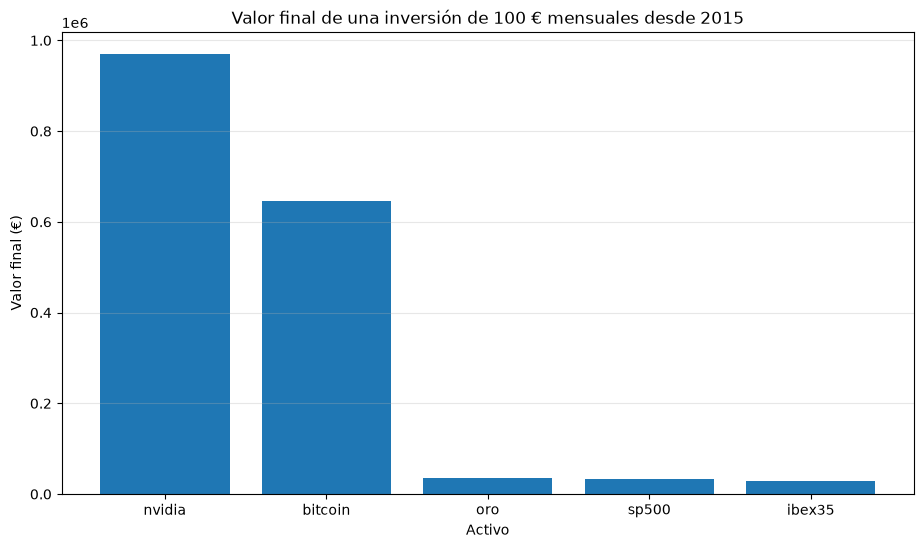

In [28]:
plt.figure(figsize=(11, 6))

plt.bar(
    tabla_comparativa["activo"],
    tabla_comparativa["valor_final"]
)

plt.title("Valor final de una inversión de 100 € mensuales desde 2015")
plt.xlabel("Activo")
plt.ylabel("Valor final (€)")
plt.grid(axis="y", alpha=0.3)

plt.show()

# CALCULAR RIESGO DE CADA INVERSIÓN: VOLATIBILIDAD Y MÁXIMA CAÍDA

In [29]:
# Definimos el periodo común de análisis
fecha_inicio_comun = "2015-01-01"
fecha_final_comun = "2026-09-01"

# Creamos una lista para guardar las métricas de riesgo
riesgo_activos = []

# Analizamos cada activo
for activo in ["sp500", "ibex35", "oro", "bitcoin", "nvidia"]:

    # Seleccionamos los precios del periodo común
    precios_periodo = precios.loc[
        fecha_inicio_comun:fecha_final_comun, activo
    ].dropna()

    # Calculamos las rentabilidades mensuales
    rentabilidades = precios_periodo.pct_change(fill_method=None).dropna()

    # Calculamos la volatilidad anualizada
    volatilidad = rentabilidades.std() * np.sqrt(12) * 100

    # Calculamos la evolución acumulada de una inversión inicial
    evolucion = (1 + rentabilidades).cumprod()

    # Añadimos el valor inicial para calcular correctamente las caídas
    evolucion = pd.concat([
        pd.Series([1], index=[precios_periodo.index[0]]),
        evolucion
    ])

    # Calculamos el máximo acumulado
    maximos = evolucion.cummax()

    # Calculamos las caídas desde los máximos
    drawdown = (evolucion / maximos) - 1

    # Identificamos la mayor caída
    max_drawdown = drawdown.min() * 100

    # Guardamos los resultados
    riesgo_activos.append({
        "activo": activo,
        "volatilidad_anualizada_pct": volatilidad,
        "max_drawdown_pct": max_drawdown
    })

# Creamos la tabla de riesgo
tabla_riesgo = pd.DataFrame(riesgo_activos)

# Redondeamos los resultados
tabla_riesgo = tabla_riesgo.round(2)

display(tabla_riesgo)

,activo,volatilidad_anualizada_pct,max_drawdown_pct
0,sp500,14.82,-19.88
1,ibex35,17.79,-44.00
2,oro,13.50,-20.65
3,bitcoin,70.39,-74.39
4,nvidia,45.03,-57.28


# AJUSTE A LA INFLACIÓN

In [30]:
# Seleccionamos los datos del IPC
ipc_periodo = ipc[["fecha", "indice_ipc"]].copy()

# Utilizamos la fecha como índice
ipc_periodo = ipc_periodo.set_index("fecha")

# Obtenemos el índice del IPC de septiembre de 2026
indice_ipc_final = ipc_periodo.loc["2026-09-01", "indice_ipc"]

print("Índice IPC septiembre 2026:", round(indice_ipc_final, 2))

Índice IPC septiembre 2026: 144.77


In [31]:
# Creamos una lista para guardar los resultados ajustados por inflación
resultados_inflacion = []

# Recorremos los cinco activos
for activo, resultado in resultados_comunes.items():

    # Unimos los resultados de la inversión con los datos del IPC
    datos_reales = resultado.join(ipc_periodo, how="inner")

    # Calculamos las aportaciones acumuladas en euros de septiembre de 2026
    aportaciones_actualizadas = (
        datos_reales["dinero_aportado"].diff().fillna(100)
        * indice_ipc_final
        / datos_reales["indice_ipc"]
    ).sum()

    # Obtenemos el valor final de la inversión
    valor_final = datos_reales["valor_cartera"].iloc[-1]

    # Calculamos la ganancia real descontando la inflación
    ganancia_real = valor_final - aportaciones_actualizadas

    # Calculamos la rentabilidad real
    rentabilidad_real = (
        ganancia_real / aportaciones_actualizadas
    ) * 100

    # Guardamos los resultados
    resultados_inflacion.append({
        "activo": activo,
        "aportaciones_nominales": datos_reales["dinero_aportado"].iloc[-1],
        "aportaciones_actualizadas": aportaciones_actualizadas,
        "valor_final": valor_final,
        "ganancia_real": ganancia_real,
        "rentabilidad_real_pct": rentabilidad_real
    })

# Creamos la tabla final
tabla_inflacion = pd.DataFrame(resultados_inflacion)

# Redondeamos los resultados
tabla_inflacion = tabla_inflacion.round(2)

display(tabla_inflacion)

,activo,aportaciones_nominales,aportaciones_actualizadas,valor_final,ganancia_real,rentabilidad_real_pct
0,sp500,14100,17073.03,32275.43,15202.40,89.04
1,ibex35,14100,17073.03,27946.68,10873.65,63.69
2,oro,14100,17073.03,34699.56,17626.54,103.24
3,bitcoin,14100,17073.03,645522.38,628449.35,3680.95
4,nvidia,14100,17073.03,969865.69,952792.67,5580.69


En este periodo, Nvidia y Bitcoin habrían generado las mayores ganancias, pero también son los activos con mayor volatilidad y riesgo de caída. El oro habría superado al S&P 500 en esta simulación concreta.

Esto no significa que Nvidia o Bitcoin vayan a repetir esos resultados en el futuro.

# RENTABILIDAD DE AHORRAR DINERO EN EL BANCO

In [32]:
# Importamos la herramienta para descargar datos
import requests
from io import StringIO

# Código de la serie del BCE:
# España, depósitos a la vista, hogares, euros
serie_bce = "M.ES.B.L21.A.R.A.2250.EUR.N"

# Construimos la dirección de la API
url_bce = (
    "https://data-api.ecb.europa.eu/service/data/MIR/"
    + serie_bce
    + "?startPeriod=2015-01&endPeriod=2026-09&format=csvdata"
)

# Descargamos los datos
respuesta = requests.get(url_bce)

# Comprobamos que la descarga ha funcionado
print("Código de respuesta:", respuesta.status_code)

# Convertimos los datos descargados en una tabla
bce_original = pd.read_csv(StringIO(respuesta.text))

# Mostramos las primeras filas
display(bce_original.head())

Código de respuesta: 200


,KEY,FREQ,REF_AREA,BS_REP_SECTOR,BS_ITEM,MATURITY_NOT_IRATE,DATA_TYPE_MIR,AMOUNT_CAT,BS_COUNT_SECTOR,CURRENCY_TRANS,...,UNIT_INDEX_BASE,COMPILATION,COVERAGE,DECIMALS,NAT_TITLE,SOURCE_AGENCY,TITLE,TITLE_COMPL,UNIT,UNIT_MULT
0,MIR.M.ES.B.L21.A.R.A.2250.EUR.N,M,ES,B,L21,A,R,A,2250,EUR,...,NaN,NaN,NaN,4,NaN,ES2,Bank interest rates on overnight deposits from...,"Spain, Annualised agreed rate (AAR) / Narrowly...",PCPA,0
1,MIR.M.ES.B.L21.A.R.A.2250.EUR.N,M,ES,B,L21,A,R,A,2250,EUR,...,NaN,NaN,NaN,4,NaN,ES2,Bank interest rates on overnight deposits from...,"Spain, Annualised agreed rate (AAR) / Narrowly...",PCPA,0
2,MIR.M.ES.B.L21.A.R.A.2250.EUR.N,M,ES,B,L21,A,R,A,2250,EUR,...,NaN,NaN,NaN,4,NaN,ES2,Bank interest rates on overnight deposits from...,"Spain, Annualised agreed rate (AAR) / Narrowly...",PCPA,0
3,MIR.M.ES.B.L21.A.R.A.2250.EUR.N,M,ES,B,L21,A,R,A,2250,EUR,...,NaN,NaN,NaN,4,NaN,ES2,Bank interest rates on overnight deposits from...,"Spain, Annualised agreed rate (AAR) / Narrowly...",PCPA,0
4,MIR.M.ES.B.L21.A.R.A.2250.EUR.N,M,ES,B,L21,A,R,A,2250,EUR,...,NaN,NaN,NaN,4,NaN,ES2,Bank interest rates on overnight deposits from...,"Spain, Annualised agreed rate (AAR) / Narrowly...",PCPA,0


In [33]:
# Mostramos todos los nombres de las columnas
print(bce_original.columns.tolist())

# Mostramos únicamente las columnas que necesitamos
display(
    bce_original[["TIME_PERIOD", "OBS_VALUE"]].head(10)
)

# Comprobamos cuántos registros tenemos
print("Número de registros:", len(bce_original))

['KEY', 'FREQ', 'REF_AREA', 'BS_REP_SECTOR', 'BS_ITEM', 'MATURITY_NOT_IRATE', 'DATA_TYPE_MIR', 'AMOUNT_CAT', 'BS_COUNT_SECTOR', 'CURRENCY_TRANS', 'IR_BUS_COV', 'TIME_PERIOD', 'OBS_VALUE', 'OBS_STATUS', 'OBS_CONF', 'OBS_PRE_BREAK', 'OBS_COM', 'TIME_FORMAT', 'BREAKS', 'COLLECTION', 'COMPILING_ORG', 'DISS_ORG', 'DOM_SER_IDS', 'PUBL_ECB', 'PUBL_MU', 'PUBL_PUBLIC', 'UNIT_INDEX_BASE', 'COMPILATION', 'COVERAGE', 'DECIMALS', 'NAT_TITLE', 'SOURCE_AGENCY', 'TITLE', 'TITLE_COMPL', 'UNIT', 'UNIT_MULT']


,TIME_PERIOD,OBS_VALUE
0,2015-01,0.16
1,2015-02,0.16
2,2015-03,0.16
3,2015-04,0.15
4,2015-05,0.16
5,2015-06,0.15
6,2015-07,0.16
7,2015-08,0.14
8,2015-09,0.13
9,2015-10,0.14


Número de registros: 141


In [34]:
# Nos quedamos únicamente con las columnas necesarias
bce = bce_original[["TIME_PERIOD", "OBS_VALUE"]].copy()

# Renombramos las columnas
bce = bce.rename(columns={
    "TIME_PERIOD": "fecha",
    "OBS_VALUE": "tipo_interes_anual_pct"
})

# Convertimos las fechas al formato de pandas
bce["fecha"] = pd.to_datetime(bce["fecha"] + "-01")

# Ordenamos los datos cronológicamente
bce = bce.sort_values("fecha").reset_index(drop=True)

# Comprobamos si existen valores ausentes
print("Dimensiones:", bce.shape)
print("Primer mes:", bce["fecha"].min())
print("Último mes:", bce["fecha"].max())
print("Valores ausentes:", bce.isna().sum().sum())

# Mostramos los primeros y últimos registros
display(bce.head())
display(bce.tail())

Dimensiones: (141, 2)
Primer mes: 2015-01-01 00:00:00
Último mes: 2026-09-01 00:00:00
Valores ausentes: 0


,fecha,tipo_interes_anual_pct
0,2015-01-01,0.16
1,2015-02-01,0.16
2,2015-03-01,0.16
3,2015-04-01,0.15
4,2015-05-01,0.16


,fecha,tipo_interes_anual_pct
136,2026-05-01,0.16
137,2026-06-01,0.15
138,2026-07-01,0.16
139,2026-08-01,0.16
140,2026-09-01,0.16


In [35]:
# Unimos los datos del BCE con el IPC
datos_banco = bce.merge(
    ipc[["fecha", "indice_ipc"]],
    on="fecha",
    how="inner"
)

# Comprobamos que tenemos los mismos meses
print("Número de meses:", len(datos_banco))

# Mostramos los primeros registros
display(datos_banco.head())

Número de meses: 141


,fecha,tipo_interes_anual_pct,indice_ipc
0,2015-01-01,0.16,107.239387
1,2015-02-01,0.16,107.453866
2,2015-03-01,0.16,108.098589
3,2015-04-01,0.15,109.071476
4,2015-05-01,0.16,109.616833


In [36]:
# Definimos la aportación mensual
aportacion_mensual = 100

# Creamos una variable para acumular el dinero
saldo_banco = 0

# Creamos una lista para guardar la evolución del ahorro
evolucion_banco = []

# Recorremos todos los meses
for _, fila in datos_banco.iterrows():

    # Obtenemos el tipo de interés anual del mes
    interes_anual = fila["tipo_interes_anual_pct"] / 100

    # Convertimos el interés anual en un interés mensual equivalente
    interes_mensual = (1 + interes_anual) ** (1/12) - 1

    # Aplicamos el interés al dinero que ya tenemos ahorrado
    saldo_banco = saldo_banco * (1 + interes_mensual)

    # Añadimos los 100 € de ese mes
    saldo_banco += aportacion_mensual

    # Guardamos el resultado
    evolucion_banco.append({
        "fecha": fila["fecha"],
        "dinero_aportado": aportacion_mensual * (len(evolucion_banco) + 1),
        "saldo_banco": saldo_banco
    })

# Convertimos la evolución en una tabla
resultado_banco = pd.DataFrame(evolucion_banco)

# Mostramos el resultado final
display(resultado_banco.tail())

print("Total aportado:", round(resultado_banco["dinero_aportado"].iloc[-1], 2), "€")
print("Saldo final en el banco:", round(resultado_banco["saldo_banco"].iloc[-1], 2), "€")

,fecha,dinero_aportado,saldo_banco
136,2026-05-01,13700,13770.156504
137,2026-06-01,13800,13871.876591
138,2026-07-01,13900,13973.724820
139,2026-08-01,14000,14075.586618
140,2026-09-01,14100,14177.461988


Total aportado: 14100 €
Saldo final en el banco: 14177.46 €


Entre 2015 y septiembre de 2026, ahorrar 100 € mensuales en una cuenta bancaria habría permitido acumular 14.177,46 €, de los cuales solo 77,46 € corresponderían a intereses. Sin embargo, esta simulación utiliza el tipo medio de los depósitos a la vista de los hogares en España publicado por el BCE, no la remuneración de una cuenta bancaria concreta. Tampoco contempla comisiones, impuestos sobre los intereses, posibles cambios en las condiciones de las cuentas ni promociones bancarias. Además, no se tiene en cuenta el efecto de la inflación en esta cantidad nominal, que reduce su poder adquisitivo. Por tanto, el resultado es una estimación orientativa del ahorro bancario, no una rentabilidad garantizada.

# COMPARACION AHORRO BANCARIO CON INVERSIONES

In [37]:
# Unimos la evolución del banco con los datos del IPC
banco_real = resultado_banco.merge(
    ipc[["fecha", "indice_ipc"]],
    on="fecha",
    how="inner"
)

# Calculamos cuánto equivalen las aportaciones en euros de septiembre de 2026
aportaciones_banco_actualizadas = (
    100 * indice_ipc_final / banco_real["indice_ipc"]
).sum()

# Obtenemos el saldo final
saldo_banco_final = banco_real["saldo_banco"].iloc[-1]

# Calculamos la ganancia real
ganancia_banco_real = (
    saldo_banco_final - aportaciones_banco_actualizadas
)

# Calculamos la rentabilidad real
rentabilidad_banco_real = (
    ganancia_banco_real / aportaciones_banco_actualizadas
) * 100

print("Aportaciones nominales:", 14100, "€")
print(
    "Aportaciones actualizadas:",
    round(aportaciones_banco_actualizadas, 2), "€"
)
print("Saldo final:", round(saldo_banco_final, 2), "€")
print("Ganancia real:", round(ganancia_banco_real, 2), "€")
print("Rentabilidad real:", round(rentabilidad_banco_real, 2), "%")

Aportaciones nominales: 14100 €
Aportaciones actualizadas: 17073.03 €
Saldo final: 14177.46 €
Ganancia real: -2895.56 €
Rentabilidad real: -16.96 %


In [38]:
# Creamos una fila con los resultados del banco
fila_banco = pd.DataFrame([{
    "activo": "banco",
    "aportaciones_nominales": 14100,
    "aportaciones_actualizadas": aportaciones_banco_actualizadas,
    "valor_final": saldo_banco_final,
    "ganancia_real": ganancia_banco_real,
    "rentabilidad_real_pct": rentabilidad_banco_real
}])

# Añadimos el banco a la tabla de inflación
tabla_comparativa_real = pd.concat(
    [tabla_inflacion, fila_banco],
    ignore_index=True
)

# Ordenamos de mayor a menor rentabilidad real
tabla_comparativa_real = tabla_comparativa_real.sort_values(
    "rentabilidad_real_pct",
    ascending=False
)

# Redondeamos los resultados
tabla_comparativa_real = tabla_comparativa_real.round(2)

display(tabla_comparativa_real)

,activo,aportaciones_nominales,aportaciones_actualizadas,valor_final,ganancia_real,rentabilidad_real_pct
4,nvidia,14100,17073.03,969865.69,952792.67,5580.69
3,bitcoin,14100,17073.03,645522.38,628449.35,3680.95
2,oro,14100,17073.03,34699.56,17626.54,103.24
0,sp500,14100,17073.03,32275.43,15202.40,89.04
1,ibex35,14100,17073.03,27946.68,10873.65,63.69
5,banco,14100,17073.03,14177.46,-2895.56,-16.96


# ¿Invertir o dejar el dinero en el banco?

Los resultados muestran que, entre enero de 2015 y septiembre de 2026, invertir 100 € mensuales habría ofrecido mejores resultados que mantener ese dinero en una cuenta bancaria a la vista. Mientras que el ahorro bancario habría generado únicamente 77,46 € en intereses y una rentabilidad real negativa del -16,96 %, debido al efecto de la inflación, todas las alternativas de inversión analizadas habrían obtenido rentabilidades reales positivas.

Nvidia habría conseguido la mayor rentabilidad real (5.580,69 %), seguida de Bitcoin (3.680,95 %). Sin embargo, ambas presentan un riesgo considerablemente mayor. Por otro lado, el oro (103,24 %), el S&P 500 (89,04 %) y el IBEX 35 (63,69 %) también habrían superado la inflación.

La principal conclusión es que ahorrar no siempre significa hacer crecer el patrimonio: cuando los intereses bancarios son inferiores a la inflación, el dinero pierde poder adquisitivo. Invertir puede ser una alternativa para preservar y aumentar ese poder adquisitivo a largo plazo, aunque implica asumir riesgos y no garantiza rentabilidades futuras.

Nota metodológica: estos resultados corresponden a un periodo histórico concreto y no garantizan que se repitan. Además, las rentabilidades de Nvidia y Bitcoin deben interpretarse teniendo en cuenta su elevada volatilidad.

# ¿CONCENTRAR O DIVERSIFICAR?

In [39]:
# Definimos la distribución de nuestra cartera
pesos_cartera = {
    "sp500": 0.60,
    "ibex35": 0.20,
    "oro": 0.10,
    "bitcoin": 0.10
}

# Definimos el periodo de inversión
fecha_inicio = "2015-01-01"
fecha_final = "2026-09-01"

# Seleccionamos los precios de los cuatro activos
precios_cartera = precios.loc[
    fecha_inicio:fecha_final,
    list(pesos_cartera.keys())
].copy()

# Comprobamos que no hay datos ausentes
print("Dimensiones de la cartera:", precios_cartera.shape)
print("\nValores ausentes:")
print(precios_cartera.isna().sum())

# Mostramos los primeros registros
display(precios_cartera.head())

Dimensiones de la cartera: (141, 4)

Valores ausentes:
sp500      0
ibex35     0
oro        0
bitcoin    0
dtype: int64


,sp500,ibex35,oro,bitcoin
fecha,,,,
2015-01-01,1767.361743,10403.289062,36.349998,192.684753
2015-02-01,1879.360506,11178.288086,34.919998,227.142212
2015-03-01,1909.365542,11521.087891,35.570000,227.396652
2015-04-01,1876.416771,11384.988281,33.919998,210.655670
2015-05-01,1922.740426,11217.587891,34.840000,210.104050


In [40]:
# Definimos la aportación mensual total
aportacion_mensual = 100

# Creamos un diccionario para guardar las participaciones de cada activo
participaciones = {
    activo: 0 for activo in pesos_cartera
}

# Creamos una lista para guardar la evolución de la cartera
evolucion_cartera = []

# Recorremos todos los meses
for fecha, fila in precios_cartera.iterrows():

    # Repartimos los 100 € según los pesos establecidos
    for activo, peso in pesos_cartera.items():

        # Calculamos cuánto dinero invertimos en cada activo
        inversion = aportacion_mensual * peso

        # Calculamos cuántas participaciones compramos
        participaciones[activo] += inversion / fila[activo]

    # Calculamos el valor de cada posición
    valores_activos = {
        activo: participaciones[activo] * fila[activo]
        for activo in pesos_cartera
    }

    # Sumamos el valor de todos los activos
    valor_total = sum(valores_activos.values())

    # Calculamos el dinero aportado hasta ese mes
    total_aportado = aportacion_mensual * (len(evolucion_cartera) + 1)

    # Guardamos los resultados
    evolucion_cartera.append({
        "fecha": fecha,
        "dinero_aportado": total_aportado,
        "valor_cartera": valor_total,
        "ganancia": valor_total - total_aportado,
        **{
            f"valor_{activo}": valor
            for activo, valor in valores_activos.items()
        }
    })

# Convertimos los resultados en una tabla
resultado_cartera = pd.DataFrame(evolucion_cartera)

# Establecemos la fecha como índice
resultado_cartera = resultado_cartera.set_index("fecha")

# Mostramos los primeros registros
display(resultado_cartera.head())

# Mostramos el resultado final
print("Total aportado:", round(resultado_cartera["dinero_aportado"].iloc[-1], 2), "€")
print("Valor final:", round(resultado_cartera["valor_cartera"].iloc[-1], 2), "€")
print("Ganancia:", round(resultado_cartera["ganancia"].iloc[-1], 2), "€")

,dinero_aportado,valor_cartera,ganancia,valor_sp500,valor_ibex35,valor_oro,valor_bitcoin
fecha,,,,,,,
2015-01-01,100,100.000000,0.000000,60.000000,20.000000,10.000000,10.000000
2015-02-01,200,206.687031,6.687031,123.802236,41.489912,19.606602,21.788282
2015-03-01,300,310.325321,10.325321,185.778807,62.762265,29.971560,31.812688
2015-04-01,400,402.645672,2.645672,242.572934,82.020849,38.581256,39.470633
2015-05-01,500,508.371209,8.371209,308.561404,100.814847,49.627684,49.367275


Total aportado: 14100 €
Valor final: 92976.79 €
Ganancia: 78876.79 €


In [41]:
# Calculamos las rentabilidades mensuales de cada activo
rentabilidades_activos = precios_cartera.pct_change(
    fill_method=None
)

# Obtenemos el valor que tenía cada activo antes de cada aportación
valores_previos = resultado_cartera[
    ["valor_sp500", "valor_ibex35", "valor_oro", "valor_bitcoin"]
].shift(1)

# Obtenemos el valor total de la cartera del mes anterior
valor_previo_total = resultado_cartera["valor_cartera"].shift(1)

# Calculamos cuánto valdrían las posiciones anteriores
# aplicando únicamente los movimientos del mercado
valor_sin_aportacion = 0

for activo in pesos_cartera:
    valor_sin_aportacion += (
        valores_previos[f"valor_{activo}"]
        * (1 + rentabilidades_activos[activo])
    )

# Calculamos la rentabilidad mensual sin nuevas aportaciones
rentabilidad_mensual_cartera = (
    valor_sin_aportacion / valor_previo_total
) - 1

rentabilidad_mensual_cartera = (
    rentabilidad_mensual_cartera.dropna()
)

# Calculamos la volatilidad anualizada
volatilidad_cartera = (
    rentabilidad_mensual_cartera.std() * np.sqrt(12) * 100
)

# Calculamos la evolución acumulada de la cartera
evolucion_cartera_riesgo = (
    1 + rentabilidad_mensual_cartera
).cumprod()

# Añadimos el valor inicial
evolucion_cartera_riesgo = pd.concat([
    pd.Series([1], index=[precios_cartera.index[0]]),
    evolucion_cartera_riesgo
])

# Calculamos el máximo acumulado
maximos_cartera = evolucion_cartera_riesgo.cummax()

# Calculamos las caídas desde los máximos
drawdown_cartera = (
    evolucion_cartera_riesgo / maximos_cartera
) - 1

# Identificamos la máxima caída
max_drawdown_cartera = drawdown_cartera.min() * 100

print("Volatilidad anualizada:", round(volatilidad_cartera, 2), "%")
print("Máximo drawdown:", round(max_drawdown_cartera, 2), "%")

Volatilidad anualizada: 41.57 %
Máximo drawdown: -58.12 %


La cartera ha sido bastante menos volátil que Bitcoin y algo menos volátil que Nvidia. Sin embargo, su máxima caída ha sido ligeramente peor que la de Nvidia. Esto es importante: diversificar reduce ciertos riesgos, pero no garantiza evitar grandes pérdidas, especialmente cuando incluimos activos muy volátiles como Bitcoin.

In [42]:
# Creamos una lista con los resultados de las tres estrategias
comparacion_estrategias = []

# Añadimos la cartera diversificada
comparacion_estrategias.append({
    "estrategia": "Cartera diversificada",
    "dinero_aportado": resultado_cartera["dinero_aportado"].iloc[-1],
    "valor_final": resultado_cartera["valor_cartera"].iloc[-1],
    "ganancia": resultado_cartera["ganancia"].iloc[-1],
    "volatilidad_pct": volatilidad_cartera,
    "max_drawdown_pct": max_drawdown_cartera
})

# Añadimos Nvidia y Bitcoin
for activo in ["nvidia", "bitcoin"]:
    resultado = resultados_comunes[activo]
    riesgo = tabla_riesgo.set_index("activo").loc[activo]

    comparacion_estrategias.append({
        "estrategia": activo.capitalize(),
        "dinero_aportado": resultado["dinero_aportado"].iloc[-1],
        "valor_final": resultado["valor_cartera"].iloc[-1],
        "ganancia": resultado["ganancia"].iloc[-1],
        "volatilidad_pct": riesgo["volatilidad_anualizada_pct"],
        "max_drawdown_pct": riesgo["max_drawdown_pct"]
    })

# Convertimos los resultados en una tabla
tabla_estrategias = pd.DataFrame(comparacion_estrategias)

# Ordenamos por valor final, de mayor a menor
tabla_estrategias = tabla_estrategias.sort_values(
    "valor_final",
    ascending=False
)

display(tabla_estrategias.round(2))

,estrategia,dinero_aportado,valor_final,ganancia,volatilidad_pct,max_drawdown_pct
1,Nvidia,14100,969865.69,955765.69,45.03,-57.28
2,Bitcoin,14100,645522.38,631422.38,70.39,-74.39
0,Cartera diversificada,14100,92976.79,78876.79,41.57,-58.12


Nvidia habría sido la estrategia más rentable, con un valor final cercano al millón de euros. Bitcoin también habría obtenido un resultado muy elevado. Sin embargo, ambos resultados dependen de haber elegido dos activos que tuvieron una evolución excepcional durante el periodo estudiado.

La cartera diversificada presenta una volatilidad del 41,57 %, inferior a la de Nvidia y Bitcoin. Frente a Bitcoin, también reduce la máxima caída del -74,39 % al -58,12 %.

No obstante, hay un matiz importante: su máxima caída fue ligeramente superior a la de Nvidia (-58,12 % frente a -57,28 %). Por tanto, diversificar no significa necesariamente que todas las medidas de riesgo vayan a ser menores que las de cualquier activo individual.

Si alguien hubiese sabido en 2015 que Nvidia iba a experimentar semejante crecimiento, concentrar allí sus aportaciones habría sido una decisión extraordinaria. Pero esa información no estaba disponible entonces. La diversificación busca reducir la dependencia de que un único activo tenga un comportamiento excepcional.

# PROYECCIÓN A FUTURO (2059) DEL SP&500

- Persona A: aporta 100 € al mes desde enero de 2010 hasta diciembre de 2059 (50 años).
- Persona B: aporta 100 € al mes desde enero de 2026 hasta diciembre de 2059 (34 años).

In [43]:
# Definimos las condiciones de la simulación
aportacion_mensual = 100
rentabilidad_anual = 0.07

# Convertimos la rentabilidad anual en una rentabilidad mensual
rentabilidad_mensual = (1 + rentabilidad_anual) ** (1/12) - 1

# Definimos los periodos de inversión
meses_persona_a = 50 * 12
meses_persona_b = 34 * 12

# Inicializamos los saldos
saldo_persona_a = 0
saldo_persona_b = 0

# Guardamos la evolución mensual
evolucion_persona_a = []
evolucion_persona_b = []

# Simulamos las aportaciones de la Persona A
for mes in range(meses_persona_a):
    saldo_persona_a = saldo_persona_a * (1 + rentabilidad_mensual)
    saldo_persona_a += aportacion_mensual

    evolucion_persona_a.append({
        "mes": mes + 1,
        "dinero_aportado": (mes + 1) * aportacion_mensual,
        "capital_acumulado": saldo_persona_a
    })

# Simulamos las aportaciones de la Persona B
for mes in range(meses_persona_b):
    saldo_persona_b = saldo_persona_b * (1 + rentabilidad_mensual)
    saldo_persona_b += aportacion_mensual

    evolucion_persona_b.append({
        "mes": mes + 1,
        "dinero_aportado": (mes + 1) * aportacion_mensual,
        "capital_acumulado": saldo_persona_b
    })

# Convertimos las listas en tablas
resultado_persona_a = pd.DataFrame(evolucion_persona_a)
resultado_persona_b = pd.DataFrame(evolucion_persona_b)

# Mostramos los resultados finales
print("PERSONA A")
print("Total aportado:", round(resultado_persona_a["dinero_aportado"].iloc[-1], 2), "€")
print("Capital acumulado:", round(resultado_persona_a["capital_acumulado"].iloc[-1], 2), "€")

print("\nPERSONA B")
print("Total aportado:", round(resultado_persona_b["dinero_aportado"].iloc[-1], 2), "€")
print("Capital acumulado:", round(resultado_persona_b["capital_acumulado"].iloc[-1], 2), "€")

PERSONA A
Total aportado: 60000 €
Capital acumulado: 503294.89 €

PERSONA B
Total aportado: 40800 €
Capital acumulado: 158788.16 €


CONCLUSIÓN ENTRE INVERSORES

In [44]:
# Creamos una tabla comparativa de las dos personas
tabla_proyeccion = pd.DataFrame([
    {
        "persona": "Persona A",
        "años_invirtiendo": 50,
        "meses_invirtiendo": meses_persona_a,
        "total_aportado": resultado_persona_a["dinero_aportado"].iloc[-1],
        "capital_final": resultado_persona_a["capital_acumulado"].iloc[-1]
    },
    {
        "persona": "Persona B",
        "años_invirtiendo": 34,
        "meses_invirtiendo": meses_persona_b,
        "total_aportado": resultado_persona_b["dinero_aportado"].iloc[-1],
        "capital_final": resultado_persona_b["capital_acumulado"].iloc[-1]
    }
])

# Calculamos la ganancia obtenida
tabla_proyeccion["ganancia"] = (
    tabla_proyeccion["capital_final"]
    - tabla_proyeccion["total_aportado"]
)

# Mostramos los resultados
display(tabla_proyeccion.round(2))

# Calculamos la diferencia entre ambas personas
diferencia_capital = (
    tabla_proyeccion.loc[0, "capital_final"]
    - tabla_proyeccion.loc[1, "capital_final"]
)

print(
    "Diferencia de capital entre Persona A y Persona B:",
    round(diferencia_capital, 2),
    "€"
)

,persona,años_invirtiendo,meses_invirtiendo,total_aportado,capital_final,ganancia
0,Persona A,50,600,60000,503294.89,443294.89
1,Persona B,34,408,40800,158788.16,117988.16


Diferencia de capital entre Persona A y Persona B: 344506.73 €


AJUSTAR A INFLACIÓN

In [45]:
# Definimos la inflación anual hipotética
inflacion_anual = 0.02

# Años transcurridos entre 2026 y 2059
años_inflacion = 33

# Calculamos cuánto aumentaría el nivel de precios
factor_inflacion = (1 + inflacion_anual) ** años_inflacion

# Convertimos el capital futuro a euros de 2026
tabla_proyeccion["capital_en_euros_2026"] = (
    tabla_proyeccion["capital_final"] / factor_inflacion
)

# Calculamos la diferencia de poder adquisitivo
diferencia_real = (
    tabla_proyeccion.loc[0, "capital_en_euros_2026"]
    - tabla_proyeccion.loc[1, "capital_en_euros_2026"]
)

# Mostramos los resultados
display(tabla_proyeccion.round(2))

print(
    "Diferencia de capital en poder adquisitivo de 2026:",
    round(diferencia_real, 2),
    "€"
)

print(
    "Factor de inflación acumulada:",
    round(factor_inflacion, 3)
)

,persona,años_invirtiendo,meses_invirtiendo,total_aportado,capital_final,ganancia,capital_en_euros_2026
0,Persona A,50,600,60000,503294.89,443294.89,261828.46
1,Persona B,34,408,40800,158788.16,117988.16,82606.16


Diferencia de capital en poder adquisitivo de 2026: 179222.3 €
Factor de inflación acumulada: 1.922


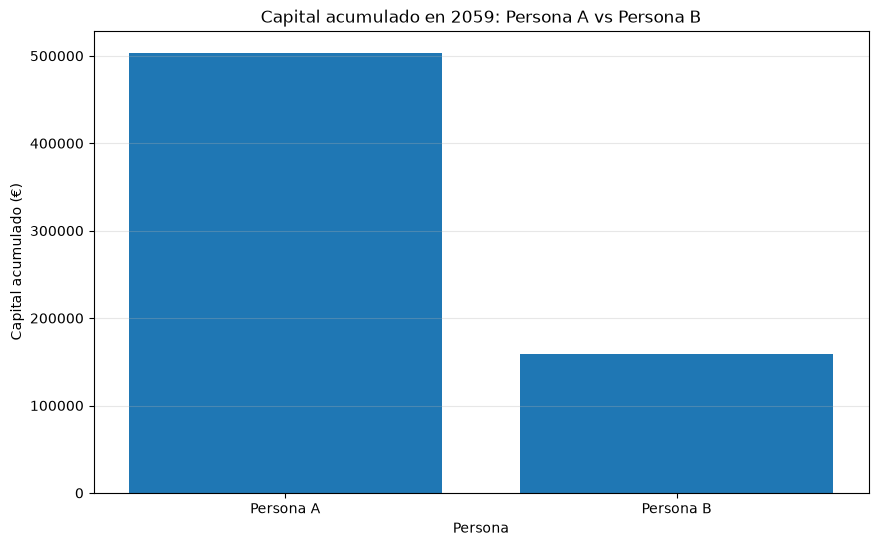

In [46]:
plt.figure(figsize=(10, 6))

plt.bar(
    tabla_proyeccion["persona"],
    tabla_proyeccion["capital_final"]
)

plt.title("Capital acumulado en 2059: Persona A vs Persona B")
plt.xlabel("Persona")
plt.ylabel("Capital acumulado (€)")
plt.grid(axis="y", alpha=0.3)

plt.show()

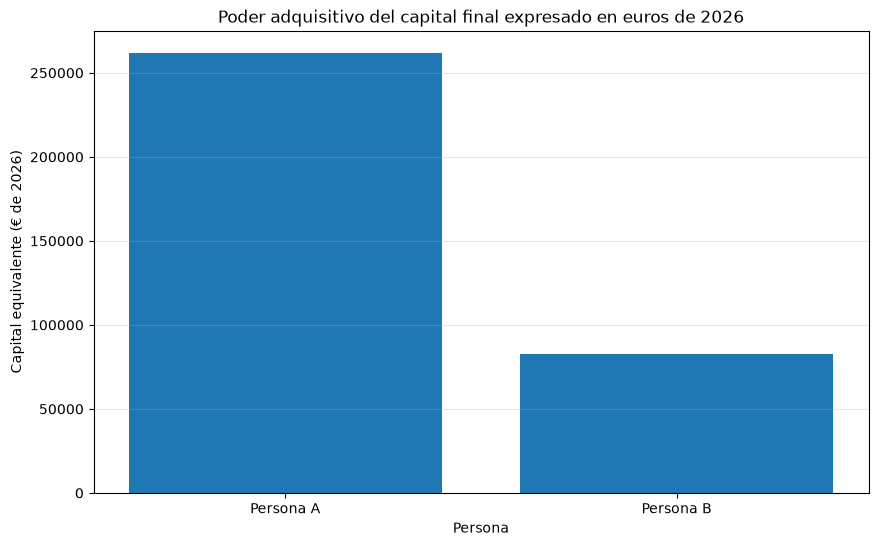

In [47]:
plt.figure(figsize=(10, 6))

plt.bar(
    tabla_proyeccion["persona"],
    tabla_proyeccion["capital_en_euros_2026"]
)

plt.title("Poder adquisitivo del capital final expresado en euros de 2026")
plt.xlabel("Persona")
plt.ylabel("Capital equivalente (€ de 2026)")
plt.grid(axis="y", alpha=0.3)

plt.show()

La simulación muestra que empezar a invertir 16 años antes puede marcar una gran diferencia en el capital acumulado. La Persona A no solo aporta más dinero, sino que también aprovecha durante más tiempo el interés compuesto, haciendo que sus rendimientos generen nuevos rendimientos. Por tanto, el tiempo es uno de los factores más importantes a la hora de construir un patrimonio a largo plazo.